# Recoleccion de datos
En este notebook se encuentra la carga inicial de los datasets crudos con el scrappeo. Tambien se encuentra la version abandonada del scrapper semanal estratificado que fue pensada para utilizar en produccion para las actualizaciones necesarias de los datasets crudos. No fue descartada porque es la forma en la que se llego al dataset final que se utilizo, que como puede verse se recupera y unifica de varias corridas de apify.
# ETL y EDA
Se encuentra una version preliminar de la limpieza de los datasets crudos para lograr el dataset final y los avances entre comparaciones estadisticas de la ingenieria de features entre los primeros intentos lineales y las graficas con datos mas establecidos.

In [ ]:
!pip install apify-client

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 15.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [apify-client]


In [ ]:
import ast
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from apify_client import ApifyClient
from google.colab import userdata

apify_token = userdata.get('APIFY_TOKEN')
client = ApifyClient(apify_token)
usuario = client.user("me").get()

print("Cuenta conectada en Colab:", usuario.username, "| Email:", usuario.email)

In [ ]:
# ==============================================================================
# PASO 1: EXTRAER Y LIMPIAR ZONAPROP DE LA SEMANA
# ==============================================================================
categorias_urls = [
    "https://www.zonaprop.com.ar/locales-comerciales-alquiler-rosario",
    "https://www.zonaprop.com.ar/oficinas-comerciales-alquiler-rosario",
    "https://www.zonaprop.com.ar/locales-comerciales-alquiler-gran-rosario",
    "https://www.zonaprop.com.ar/oficinas-comerciales-alquiler-gran-rosario"
]
urls_zp = [f"{base}.html" for base in categorias_urls] + [
    f"{base}-pagina-{p}.html" for base in categorias_urls for p in range(2, 10)
]

run_zp = client.actor("ecomscrape/zonaprop-property-listings-scraper").call(
    run_input={
        "ignore_url_failures": True,
        "max_items_per_url": 30,
        "max_retries_per_url": 1,
        "proxy": {"useApifyProxy": True, "apifyProxyGroups": ["RESIDENTIAL"], "apifyProxyCountry": "AR"},
        "urls": urls_zp
    },
    logger=None
)
df_zp_raw = pd.json_normalize(list(client.dataset(run_zp.default_dataset_id).iterate_items()), sep='/')

# Filtrar coordenadas reales de Rosario + Gran Rosario
df_zp_raw['lat'] = pd.to_numeric(df_zp_raw['posting_location/posting_geolocation/geolocation/latitude'], errors='coerce')
df_zp_raw['lon'] = pd.to_numeric(df_zp_raw['posting_location/posting_geolocation/geolocation/longitude'], errors='coerce')
zp_activo = df_zp_raw[
    (df_zp_raw['lat'].between(-33.05, -32.70)) &
    (df_zp_raw['lon'].between(-60.95, -60.60))
].dropna(subset=['lat', 'lon']).copy()

print(f"Zonaprop semanal limpio: {len(zp_activo)} propiedades activas en Rosario.")

In [ ]:
# ==============================================================================
# PASO 2: CLUSTERING DINÁMICO PARA ESTRATIFICAR GOOGLE MAPS SEGÚN ZONAPROP
# ==============================================================================
PRESUPUESTO_TOTAL_GM = 2000  # Tope objetivo de comercios únicos (dentro de 700-2000)
N_CLUSTERS = 6               # Cantidad de polos geográficos dinámicos
RUBROS = [
    "tienda", "restaurante", "cafeteria", "farmacia",
    "supermercado", "banco", "ferreteria", "panaderia",
    "peluqueria", "gimnasio", "libreria", "heladeria"
]

# Agrupar las propiedades de esta semana en 6 polos espaciales
kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
zp_activo['cluster'] = kmeans.fit_predict(zp_activo[['lat', 'lon']])

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2 - lon1)/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

todos_los_comercios = []

for cid in range(N_CLUSTERS):
    grupo = zp_activo[zp_activo['cluster'] == cid]
    if len(grupo) == 0:
        continue

    # Centroide dinámico del clúster esta semana
    c_lat, c_lon = kmeans.cluster_centers_[cid]

    # Radio dinámico: cubre el percentil 90 de propiedades del clúster (mínimo 1.5 km, máximo 4.5 km)
    dists = haversine_km(c_lat, c_lon, grupo['lat'].values, grupo['lon'].values)
    radio_dinamico = float(np.clip(np.percentile(dists, 90) + 0.4, 1.5, 4.5))

    # Cupo proporcional a la cantidad de propiedades de Zonaprop en este clúster
    proporcion = len(grupo) / len(zp_activo)
    cupo_cluster = max(60, int(PRESUPUESTO_TOTAL_GM * proporcion))
    max_por_rubro = max(5, int(cupo_cluster / len(RUBROS)))

    # Activar deeperCityScrape automáticamente solo en clústeres densos (>15% de la oferta)
    usar_deeper = proporcion >= 0.15

    print(f"Clúster {cid+1}: {len(grupo)} props ({proporcion:.1%}) -> Centro ({c_lat:.4f}, {c_lon:.4f}), radio {radio_dinamico:.1f} km, cupo ~{cupo_cluster}")

    gm_input = {
        "customGeolocation": {
            "type": "Point",
            "coordinates": [float(c_lon), float(c_lat)], # GeoJSON: [lon, lat]
            "radiusKm": round(radio_dinamico, 2)
        },
        "searchStringsArray": RUBROS,
        "maxCrawledPlacesPerSearch": max_por_rubro,
        "language": "es",
        "deeperCityScrape": usar_deeper
    }

    run_gm = client.actor("compass/crawler-google-places").call(run_input=gm_input, logger=None)
    items_gm = list(client.dataset(run_gm.default_dataset_id).iterate_items())
    todos_los_comercios.extend(items_gm)


In [ ]:

# ==============================================================================
# PASO 3: CONSOLIDAR Y EXPORTAR SNAPSHOT SEMANAL
# ==============================================================================
df_gm = pd.json_normalize(todos_los_comercios, sep='/')
df_gm = df_gm.drop_duplicates(subset=['placeId'])
if 'permanentlyClosed' in df_gm.columns:
    df_gm = df_gm[df_gm['permanentlyClosed'] != True]
#df_gm = df_gm.head(2000)

print(f"\nSnapshot semanal completado: {len(zp_activo)} propiedades | {len(df_gm)} comercios alineados.")

In [ ]:
# 1. Guardar en el almacenamiento temporal de Colab
df_zp.to_csv("zonaprop_rosario_crudo.csv", index=False, encoding="utf-8-sig")
df_gm.to_csv("google_maps_rosario_crudo.csv", index=False, encoding="utf-8-sig")

print("Archivos CSV guardados correctamente.")

# 2. Descargarlos automáticamente a tu computadora (opcional pero recomendado)
from google.colab import files
files.download("zonaprop_rosario_crudo.csv")
files.download("google_maps_rosario_crudo.csv")

In [ ]:
import ast
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from apify_client import ApifyClient

# Constantes de configuración del pipeline
TIPO_CAMBIO_USD = 1600
TTL_DIAS_MAPS = 45               # Vigencia de los comercios en el maestro antes de refrescar
MIN_VECINOS_CUBIERTOS = 5        # Mínimo de comercios en 350m para considerar cubierta una propiedad
PRESUPUESTO_MAPS = 2000          # Tope de lugares en el dataset por el limite de la profe
PRESUPUESTO_SEMANAL_MAPS = 600   # Tope máximo de lugares nuevos a scrapear por semana

RUBROS_MAPS = [
    "tienda", "restaurante", "cafeteria", "farmacia",
    "supermercado", "banco", "ferreteria", "panaderia",
    "peluqueria", "gimnasio", "libreria", "heladeria"
]

def haversine_m(lat1, lon1, lat2_arr, lon2_arr):
    R = 6371000.0
    lat1, lon1, lat2_arr, lon2_arr = map(np.radians, [lat1, lon1, lat2_arr, lon2_arr])
    dlat = lat2_arr - lat1
    dlon = lon2_arr - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2_arr) * np.sin(dlon / 2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

def _parse_price_info(val):
    if pd.isna(val):
        return np.nan, np.nan, np.nan
    try:
        data = ast.literal_eval(val) if isinstance(val, str) else val
        if isinstance(data, list) and len(data) > 0:
            op = data[0].get('operation_type', {}).get('name', np.nan)
            prices = data[0].get('prices', [])
            if len(prices) > 0:
                return op, prices[0].get('amount', np.nan), prices[0].get('currency', np.nan)
    except Exception:
        pass
    return np.nan, np.nan, np.nan

def ejecutar_scrapeo_semanal_unificado(apify_token: str, df_maestro_previo: pd.DataFrame):
    client = ApifyClient(apify_token)
    hoy = pd.Timestamp.now().normalize()

    # ==========================================================================
    # PASO 1: EXTRACCIÓN Y LIMPIEZA DE ZONAPROP (OFERTA ACTIVA DE LA SEMANA)
    # ==========================================================================
    categorias_urls = [
        "https://www.zonaprop.com.ar/locales-comerciales-alquiler-rosario",
        "https://www.zonaprop.com.ar/oficinas-comerciales-alquiler-rosario"
    ]
    urls_zp = [f"{base}.html" for base in categorias_urls] + [
        f"{base}-pagina-{p}.html" for base in categorias_urls for p in range(2, 10)
    ]

    run_zp = client.actor("ecomscrape/zonaprop-property-listings-scraper").call(
        run_input={
            "ignore_url_failures": True,
            "max_items_per_url": 30,
            "max_retries_per_url": 1,
            "proxy": {"useApifyProxy": True, "apifyProxyGroups": ["RESIDENTIAL"], "apifyProxyCountry": "AR"},
            "urls": urls_zp
        },
        logger=None
    )
    df_zp_raw = pd.json_normalize(list(client.dataset(run_zp.default_dataset_id).iterate_items()), sep='/')

    parsed = df_zp_raw['price_operation_types'].apply(_parse_price_info)
    zp_clean = pd.DataFrame({
        'posting_id': df_zp_raw.get('posting_id', pd.Series(range(len(df_zp_raw)))),
        'lat': pd.to_numeric(df_zp_raw['posting_location/posting_geolocation/geolocation/latitude'], errors='coerce'),
        'lon': pd.to_numeric(df_zp_raw['posting_location/posting_geolocation/geolocation/longitude'], errors='coerce'),
        'barrio': df_zp_raw['posting_location/location/name'],
        'ciudad': df_zp_raw['posting_location/location/parent/name'],
        'tipo_inmueble': df_zp_raw['real_estate_type/name'],
        'tipo_operacion': [x[0] for x in parsed],
        'precio_crudo': pd.to_numeric([x[1] for x in parsed], errors='coerce'),
        'moneda': [x[2] for x in parsed],
        'expensas_ars': pd.to_numeric(df_zp_raw.get('expenses/amount', 0), errors='coerce').fillna(0),
        'superficie_m2': pd.to_numeric(df_zp_raw['main_features/c_f_t100/value'], errors='coerce')
    }).drop_duplicates(subset=['posting_id'])

    # Filtrar Rosario + Gran Rosario, solo Alquileres y rangos lógicos
    zp_clean = zp_clean.dropna(subset=['lat', 'lon', 'precio_crudo', 'superficie_m2', 'moneda', 'tipo_operacion'])
    zp_clean = zp_clean[
        (zp_clean['lat'].between(-33.05, -32.70)) &
        (zp_clean['lon'].between(-60.95, -60.60)) &
        (zp_clean['tipo_operacion'] == 'Alquiler') &
        (zp_clean['superficie_m2'].between(10, 2000))
    ].copy()

    es_pesos = zp_clean['moneda'].isin(['$', 'ARS'])
    zp_clean['precio_usd'] = np.where(es_pesos, zp_clean['precio_crudo'] / TIPO_CAMBIO_USD, zp_clean['precio_crudo'])
    zp_clean['precio_ars'] = np.where(~es_pesos, zp_clean['precio_crudo'] * TIPO_CAMBIO_USD, zp_clean['precio_crudo'])
    zp_clean = zp_clean[(zp_clean['precio_usd'] > 20) & (zp_clean['precio_ars'] <= zp_clean['precio_ars'].quantile(0.98))].copy()
    zp_clean['precio_m2_usd'] = (zp_clean['precio_usd'] / zp_clean['superficie_m2']).round(2)

    # ==========================================================================
    # PASO 2: ACTUALIZACIÓN INCREMENTAL DE GOOGLE MAPS (CACHÉ TTL + KMEANS)
    # ==========================================================================
    # 2.1 Filtrar comercios vigentes del maestro previo
    if df_maestro_previo is not None and not df_maestro_previo.empty:
        df_maestro_previo['fecha_extraccion'] = pd.to_datetime(df_maestro_previo['fecha_extraccion'])
        df_gm_vigente = df_maestro_previo[(hoy - df_maestro_previo['fecha_extraccion']).dt.days <= TTL_DIAS_MAPS].copy()
    else:
        df_gm_vigente = pd.DataFrame(columns=['placeId', 'lat', 'lon', 'nombre', 'rubro', 'resenas', 'fecha_extraccion'])

    # 2.2 Detectar propiedades de Zonaprop sin cobertura vigente (< MIN_VECINOS_CUBIERTOS en 350m)
    huerfanas = []
    for _, row in zp_clean.iterrows():
        if df_gm_vigente.empty:
            huerfanas.append(row)
        else:
            dists = haversine_m(row['lat'], row['lon'], df_gm_vigente['lat'].values, df_gm_vigente['lon'].values)
            if (dists <= 350).sum() < MIN_VECINOS_CUBIERTOS:
                huerfanas.append(row)

    df_huerfanas = pd.DataFrame(huerfanas)

    # 2.3 Scrapear Google Maps SOLO sobre los clústeres de propiedades descubiertas
    if not df_huerfanas.empty:
        # Si es la carga inicial (maestro vacío), usar 6 clústeres y presupuesto completo (1800)
        es_carga_inicial = df_gm_vigente.empty
        n_clusters = min(6 if es_carga_inicial else 4, len(df_huerfanas))
        presupuesto = 1800 if es_carga_inicial else PRESUPUESTO_SEMANAL_MAPS

        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        df_huerfanas['cluster'] = kmeans.fit_predict(df_huerfanas[['lat', 'lon']])

        nuevos_items = []
        for cid in range(n_clusters):
            grupo = df_huerfanas[df_huerfanas['cluster'] == cid]
            c_lat, c_lon = kmeans.cluster_centers_[cid]
            dists_km = haversine_m(c_lat, c_lon, grupo['lat'].values, grupo['lon'].values) / 1000.0
            radio_km = float(np.clip(np.percentile(dists_km, 90) + 0.4, 1.5, 4.5))

            proporcion = len(grupo) / len(df_huerfanas)
            cupo = max(50, int(presupuesto * proporcion))
            max_rubro = max(5, int(cupo / len(RUBROS_MAPS)))

            run_gm = client.actor("compass/crawler-google-places").call(
                run_input={
                    "customGeolocation": {"type": "Point", "coordinates": [float(c_lon), float(c_lat)], "radiusKm": round(radio_km, 2)},
                    "searchStringsArray": RUBROS_MAPS,
                    "maxCrawledPlacesPerSearch": max_rubro,
                    "language": "es",
                    "deeperCityScrape": proporcion >= 0.15
                },
                logger=None
            )
            nuevos_items.extend(list(client.dataset(run_gm.default_dataset_id).iterate_items()))

        if nuevos_items:
            df_nuevos_raw = pd.json_normalize(nuevos_items, sep='/')
            if 'permanentlyClosed' in df_nuevos_raw.columns:
                df_nuevos_raw = df_nuevos_raw[df_nuevos_raw['permanentlyClosed'] != True]

            df_nuevos = pd.DataFrame({
                'placeId': df_nuevos_raw['placeId'],
                'lat': pd.to_numeric(df_nuevos_raw['location/lat'], errors='coerce'),
                'lon': pd.to_numeric(df_nuevos_raw['location/lng'], errors='coerce'),
                'nombre': df_nuevos_raw['title'],
                'rubro': df_nuevos_raw.get('categoryName', 'Comercio'),
                'resenas': pd.to_numeric(df_nuevos_raw['reviewsCount'], errors='coerce').fillna(0),
                'fecha_extraccion': hoy
            }).dropna(subset=['placeId', 'lat', 'lon'])

            # Upsert en el maestro vigente (actualiza reseñas y fecha si ya existía)
            df_gm_vigente = pd.concat([df_gm_vigente, df_nuevos], ignore_index=True)
            df_gm_vigente = df_gm_vigente.drop_duplicates(subset=['placeId'], keep='last').head(2000)

    # ==========================================================================
    # PASO 3: CRUCE GEOESPACIAL FINAL (ZONAPROP + MAESTRO GOOGLE MAPS ACTUALIZADO)
    # ==========================================================================
    dens200, res200, dens350, res350 = [], [], [], []
    gm_lat = df_gm_vigente['lat'].values
    gm_lon = df_gm_vigente['lon'].values
    gm_res = df_gm_vigente['resenas'].values

    for _, row in zp_clean.iterrows():
        d = haversine_m(row['lat'], row['lon'], gm_lat, gm_lon)
        m200 = d <= 200
        m350 = d <= 350
        dens200.append(int(m200.sum()))
        res200.append(float(gm_res[m200].sum()))
        dens350.append(int(m350.sum()))
        res350.append(float(gm_res[m350].sum()))

    zp_clean['densidad_comercial_200m'] = dens200
    zp_clean['trafico_resenas_200m'] = res200
    zp_clean['densidad_comercial_350m'] = dens350
    zp_clean['trafico_resenas_350m'] = res350
    zp_clean['resenas_por_comercio_350m'] = (
        zp_clean['trafico_resenas_350m'] / (zp_clean['densidad_comercial_350m'] + 1)
    ).round(1)

    return zp_clean, df_gm_vigente

In [ ]:
import os
import ast
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from apify_client import ApifyClient
from google.colab import userdata

# ==============================================================================
# CONFIGURACIÓN GLOBAL (Reemplazá con tu token real)
# ==============================================================================
APIFY_TOKEN = userdata.get('APIFY_TOKEN')

ARCHIVO_MAESTRO_GM = "maestro_comercios_rosario.csv"
ARCHIVO_DATASET_FINAL = "dataset_inmobiliario_completo_rosario.csv"

TIPO_CAMBIO_USD = 1600
TTL_DIAS_MAPS = 45               # Vigencia de comercios en caché antes de refrescar
MIN_VECINOS_CUBIERTOS = 5        # Mínimo de comercios en 350m para considerar cubierta una propiedad
PRESUPUESTO_INICIAL_MAPS = 2100  # Tope en la carga inicial
PRESUPUESTO_SEMANAL_MAPS = 700   # Tope en actualizaciones semanales

RUBROS_MAPS = [
    "tienda", "restaurante", "cafeteria", "farmacia",
    "supermercado", "banco", "ferreteria", "panaderia",
    "peluqueria", "gimnasio", "libreria", "heladeria"
]

# ==============================================================================
# FUNCIONES AUXILIARES
# ==============================================================================
def haversine_m(lat1, lon1, lat2_arr, lon2_arr):
    R = 6371000.0
    lat1, lon1, lat2_arr, lon2_arr = map(np.radians, [lat1, lon1, lat2_arr, lon2_arr])
    dlat = lat2_arr - lat1
    dlon = lon2_arr - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2_arr) * np.sin(dlon / 2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

def parse_price_info(val):
    if isinstance(val, str):
        try:
            data = ast.literal_eval(val)
        except Exception:
            return np.nan, np.nan, np.nan
    elif isinstance(val, list):
        data = val
    else:
        return np.nan, np.nan, np.nan

    if len(data) > 0 and isinstance(data[0], dict):
        op = data[0].get('operation_type', {}).get('name', np.nan)
        prices = data[0].get('prices', [])
        if len(prices) > 0 and isinstance(prices[0], dict):
            return op, prices[0].get('amount', np.nan), prices[0].get('currency', np.nan)

    return np.nan, np.nan, np.nan

# ==============================================================================
# PIPELINE UNIFICADO DE 3 PASOS
# ==============================================================================
def ejecutar_scrapeo_semanal_unificado(apify_token: str, df_maestro_previo: pd.DataFrame):
    client = ApifyClient(apify_token)
    hoy = pd.Timestamp.now().normalize()

    # --------------------------------------------------------------------------
    # PASO 1: EXTRACCIÓN Y LIMPIEZA DE ZONAPROP
    # --------------------------------------------------------------------------
    print("[PASO 1/3] Extrayendo oferta comercial activa en Zonaprop...")
    categorias_urls = [
      "https://www.zonaprop.com.ar/locales-comerciales-alquiler-rosario",
      "https://www.zonaprop.com.ar/oficinas-comerciales-alquiler-rosario",
      "https://www.zonaprop.com.ar/locales-comerciales-alquiler-gran-rosario",
      "https://www.zonaprop.com.ar/oficinas-comerciales-alquiler-gran-rosario"
    ]
    urls_zp = [f"{base}.html" for base in categorias_urls] + [
      f"{base}-pagina-{p}.html" for base in categorias_urls for p in range(2, 10)
    ]

    run_zp = client.actor("ecomscrape/zonaprop-property-listings-scraper").call(
        run_input={
            "ignore_url_failures": True,
            "max_items_per_url": 30,
            "max_retries_per_url": 1,
            "proxy": {"useApifyProxy": True, "apifyProxyGroups": ["RESIDENTIAL"], "apifyProxyCountry": "AR"},
            "urls": urls_zp
        },
        logger=None
    )
    df_zp_raw = pd.json_normalize(list(client.dataset(run_zp.default_dataset_id).iterate_items()), sep='/')

    # Recupera los datos de la última corrida exitosa de Zonaprop sin gastar créditos
    # last_run = client.actor("ecomscrape/zonaprop-property-listings-scraper").last_run(status="SUCCEEDED").get()
    # items_zp = list(client.dataset(last_run.default_dataset_id).iterate_items())
    # df_zp_raw = pd.json_normalize(items_zp, sep='/')
    # print(f"Recuperados {len(df_zp_raw)} registros del run {last_run.id} sin gastar créditos.")

    parsed = df_zp_raw['price_operation_types'].apply(parse_price_info)
    zp_clean = pd.DataFrame({
        'posting_id': df_zp_raw.get('posting_id', pd.Series(range(len(df_zp_raw)))),
        'lat': pd.to_numeric(df_zp_raw['posting_location/posting_geolocation/geolocation/latitude'], errors='coerce'),
        'lon': pd.to_numeric(df_zp_raw['posting_location/posting_geolocation/geolocation/longitude'], errors='coerce'),
        'barrio': df_zp_raw['posting_location/location/name'],
        'ciudad': df_zp_raw['posting_location/location/parent/name'],
        'tipo_inmueble': df_zp_raw['real_estate_type/name'],
        'tipo_operacion': [x[0] for x in parsed],
        'precio_crudo': pd.to_numeric([x[1] for x in parsed], errors='coerce'),
        'moneda': [x[2] for x in parsed],
        'expensas_ars': pd.to_numeric(df_zp_raw.get('expenses/amount', 0), errors='coerce').fillna(0),
        'superficie_m2': pd.to_numeric(df_zp_raw['main_features/c_f_t100/value'], errors='coerce')
    }).drop_duplicates(subset=['posting_id'])

    # Filtrar Rosario + Gran Rosario, solo Alquileres y rangos lógicos
    zp_clean = zp_clean.dropna(subset=['lat', 'lon', 'precio_crudo', 'superficie_m2', 'moneda', 'tipo_operacion'])
    zp_clean = zp_clean[
        (zp_clean['lat'].between(-33.05, -32.70)) &
        (zp_clean['lon'].between(-60.95, -60.60)) &
        (zp_clean['tipo_operacion'] == 'Alquiler') &
        (zp_clean['superficie_m2'].between(10, 2000))
    ].copy()

    es_pesos = zp_clean['moneda'].isin(['$', 'ARS'])
    zp_clean['precio_usd'] = np.where(es_pesos, zp_clean['precio_crudo'] / TIPO_CAMBIO_USD, zp_clean['precio_crudo'])
    zp_clean['precio_ars'] = np.where(~es_pesos, zp_clean['precio_crudo'] * TIPO_CAMBIO_USD, zp_clean['precio_crudo'])
    zp_clean = zp_clean[(zp_clean['precio_usd'] > 20) & (zp_clean['precio_ars'] <= zp_clean['precio_ars'].quantile(0.98))].copy()
    zp_clean['precio_m2_usd'] = (zp_clean['precio_usd'] / zp_clean['superficie_m2']).round(2)

    print(f" -> Zonaprop limpio: {len(zp_clean)} propiedades activas en Rosario.")

    # --------------------------------------------------------------------------
    # PASO 2: ACTUALIZACIÓN INCREMENTAL DE GOOGLE MAPS (CACHÉ TTL + KMEANS)
    # --------------------------------------------------------------------------
    print("[PASO 2/3] Evaluando cobertura geográfica en el maestro de Google Maps...")
    if df_maestro_previo is not None and not df_maestro_previo.empty:
        df_maestro_previo['fecha_extraccion'] = pd.to_datetime(df_maestro_previo['fecha_extraccion'])
        df_gm_vigente = df_maestro_previo[(hoy - df_maestro_previo['fecha_extraccion']).dt.days <= TTL_DIAS_MAPS].copy()
        print(f" -> Maestro previo cargado: {len(df_gm_vigente)} comercios vigentes (TTL <= {TTL_DIAS_MAPS} días).")
    else:
        df_gm_vigente = pd.DataFrame(columns=['placeId', 'lat', 'lon', 'nombre', 'rubro', 'resenas', 'fecha_extraccion'])
        print(" -> Sin maestro previo: se ejecutará carga inicial completa.")

    huerfanas = []
    for _, row in zp_clean.iterrows():
        if df_gm_vigente.empty:
            huerfanas.append(row)
        else:
            dists = haversine_m(row['lat'], row['lon'], df_gm_vigente['lat'].values, df_gm_vigente['lon'].values)
            if (dists <= 350).sum() < MIN_VECINOS_CUBIERTOS:
                huerfanas.append(row)

    df_huerfanas = pd.DataFrame(huerfanas)
    print(f" -> Propiedades sin cobertura vigente (<{MIN_VECINOS_CUBIERTOS} comercios a 350m): {len(df_huerfanas)}")

    if df_huerfanas.empty:
        print(" -> Cobertura al 100%. No hace falta ejecutar Google Maps esta semana.")
    else:
        es_carga_inicial = df_gm_vigente.empty
        n_clusters = min(6 if es_carga_inicial else 4, len(df_huerfanas))
        presupuesto = PRESUPUESTO_INICIAL_MAPS if es_carga_inicial else PRESUPUESTO_SEMANAL_MAPS

        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        df_huerfanas['cluster'] = kmeans.fit_predict(df_huerfanas[['lat', 'lon']])

        nuevos_items = []
        for cid in range(n_clusters):
            grupo = df_huerfanas[df_huerfanas['cluster'] == cid]
            c_lat, c_lon = kmeans.cluster_centers_[cid]
            dists_km = haversine_m(c_lat, c_lon, grupo['lat'].values, grupo['lon'].values) / 1000.0
            radio_km = float(np.clip(np.percentile(dists_km, 90) + 0.4, 1.5, 4.5))

            proporcion = len(grupo) / len(df_huerfanas)
            cupo = max(50, int(presupuesto * proporcion))
            max_rubro = max(5, int(cupo / len(RUBROS_MAPS)))

            print(f"    * Scrapeando clúster {cid+1}/{n_clusters}: {len(grupo)} props ({proporcion:.1%}), centro ({c_lat:.4f}, {c_lon:.4f}), radio {radio_km:.1f} km...")
            run_gm = client.actor("compass/crawler-google-places").call(
                run_input={
                    "customGeolocation": {"type": "Point", "coordinates": [float(c_lon), float(c_lat)], "radiusKm": round(radio_km, 2)},
                    "searchStringsArray": RUBROS_MAPS,
                    "maxCrawledPlacesPerSearch": max_rubro,
                    "language": "es",
                    "deeperCityScrape": False,          # Evita subdividir en decenas de cuadrículas pagas
                    "scrapePlaceDetailPage": False,     # CLAVE: No entra ficha por ficha; lee directo de la lista (ahorra ~80% de créditos)
                    "maxReviews": 0,                    # No descarga textos de reseñas (reviewsCount igual viene en la lista)
                    "maxImages": 0,                     # No descarga URLs de fotos
                    "scrapeContacts": False             # No rastrea emails ni redes sociales
                },
                logger=None
            )
            nuevos_items.extend(list(client.dataset(run_gm.default_dataset_id).iterate_items()))

        if nuevos_items:
            df_nuevos_raw = pd.json_normalize(nuevos_items, sep='/')
            if 'permanentlyClosed' in df_nuevos_raw.columns:
                df_nuevos_raw = df_nuevos_raw[df_nuevos_raw['permanentlyClosed'] != True]

            df_nuevos = pd.DataFrame({
                'placeId': df_nuevos_raw['placeId'],
                'lat': pd.to_numeric(df_nuevos_raw['location/lat'], errors='coerce'),
                'lon': pd.to_numeric(df_nuevos_raw['location/lng'], errors='coerce'),
                'nombre': df_nuevos_raw['title'],
                'rubro': df_nuevos_raw.get('categoryName', 'Comercio'),
                'resenas': pd.to_numeric(df_nuevos_raw['reviewsCount'], errors='coerce').fillna(0),
                'fecha_extraccion': hoy
            }).dropna(subset=['placeId', 'lat', 'lon'])

            df_gm_vigente = pd.concat([df_gm_vigente, df_nuevos], ignore_index=True)
            df_gm_vigente = df_gm_vigente.drop_duplicates(subset=['placeId'], keep='last').head(PRESUPUESTO_INICIAL_MAPS)
            print(f" -> Maestro Google Maps actualizado: {len(df_gm_vigente)} comercios únicos vigentes.")

    # --------------------------------------------------------------------------
    # PASO 3: CRUCE GEOESPACIAL FINAL (HAVERSINE)
    # --------------------------------------------------------------------------
    print("[PASO 3/3] Calculando densidad comercial y tráfico de reseñas...")
    dens200, res200, dens350, res350 = [], [], [], []
    gm_lat = df_gm_vigente['lat'].values
    gm_lon = df_gm_vigente['lon'].values
    gm_res = df_gm_vigente['resenas'].values

    for _, row in zp_clean.iterrows():
        d = haversine_m(row['lat'], row['lon'], gm_lat, gm_lon)
        m200 = d <= 200
        m350 = d <= 350
        dens200.append(int(m200.sum()))
        res200.append(float(gm_res[m200].sum()))
        dens350.append(int(m350.sum()))
        res350.append(float(gm_res[m350].sum()))

    zp_clean['densidad_comercial_200m'] = dens200
    zp_clean['trafico_resenas_200m'] = res200
    zp_clean['densidad_comercial_350m'] = dens350
    zp_clean['trafico_resenas_350m'] = res350
    zp_clean['resenas_por_comercio_350m'] = (
        zp_clean['trafico_resenas_350m'] / (zp_clean['densidad_comercial_350m'] + 1)
    ).round(1)

    return zp_clean, df_gm_vigente

# ==============================================================================
# MAIN DE PRUEBA PARA GOOGLE COLAB
# ==============================================================================
def main():
    print("=== INICIANDO TEST DE CARGA SEMANAL - INMOBIFY ===\n")

    # 1. Simular lectura del Key-Value Store desde disco local de Colab
    if os.path.exists(ARCHIVO_MAESTRO_GM):
        df_maestro_previo = pd.read_csv(ARCHIVO_MAESTRO_GM)
    else:
        df_maestro_previo = pd.DataFrame()

    # 2. Ejecutar el pipeline unificado de 3 pasos
    df_dataset_final, df_maestro_actualizado = ejecutar_scrapeo_semanal_unificado(
        apify_token=APIFY_TOKEN,
        df_maestro_previo=df_maestro_previo
    )

    # 3. Persistir ambos CSVs en Colab
    df_maestro_actualizado.to_csv(ARCHIVO_MAESTRO_GM, index=False, encoding="utf-8-sig")
    df_dataset_final.to_csv(ARCHIVO_DATASET_FINAL, index=False, encoding="utf-8-sig")

    print("\n=== RESUMEN DE EJECUCIÓN ===")
    print(f"1. Maestro Google Maps guardado en '{ARCHIVO_MAESTRO_GM}': {len(df_maestro_actualizado)} comercios")
    print(f"2. Dataset Inmobiliario guardado en '{ARCHIVO_DATASET_FINAL}': {len(df_dataset_final)} propiedades")
    print(f"3. Cobertura lograda (% de locales con >0 comercios a 350m): {(df_dataset_final['densidad_comercial_350m'] > 0).mean():.1%}")
    print("\nVista previa del dataset listo para entrenar ML:")
    display(df_dataset_final[['barrio', 'tipo_inmueble', 'superficie_m2', 'precio_usd', 'densidad_comercial_350m', 'trafico_resenas_350m']].head(10))

if __name__ == "__main__":
    main()

=== INICIANDO TEST DE CARGA SEMANAL - INMOBIFY ===

[PASO 1/3] Extrayendo oferta comercial activa en Zonaprop...
Recuperados 1079 registros del run Wk1FoBhifRT0Kmkiy sin gastar créditos.
 -> Zonaprop limpio: 477 propiedades activas en Rosario.
[PASO 2/3] Evaluando cobertura geográfica en el maestro de Google Maps...
 -> Maestro previo cargado: 2000 comercios vigentes (TTL <= 45 días).
 -> Propiedades sin cobertura vigente (<5 comercios a 350m): 86
    * Scrapeando clúster 1/4: 43 props (50.0%), centro (-32.9285, -60.6656), radio 2.1 km...
    * Scrapeando clúster 2/4: 12 props (14.0%), centro (-32.9325, -60.7663), radio 4.5 km...
    * Scrapeando clúster 3/4: 13 props (15.1%), centro (-32.9116, -60.7007), radio 4.1 km...
    * Scrapeando clúster 4/4: 18 props (20.9%), centro (-32.9892, -60.6565), radio 4.5 km...
 -> Maestro Google Maps actualizado: 2100 comercios únicos vigentes.
[PASO 3/3] Calculando densidad comercial y tráfico de reseñas...

=== RESUMEN DE EJECUCIÓN ===
1. Maestro G

,barrio,tipo_inmueble,superficie_m2,precio_usd,densidad_comercial_350m,trafico_resenas_350m
1,Echesortu,Locales Comerciales,120.0,1562.50,6,4378.0
2,Nuestra Señora de Lourdes,Locales Comerciales,145.0,1437.50,65,10848.0
3,Fisherton,Locales Comerciales,32.0,406.25,2,939.0
4,Centro,Locales Comerciales,334.0,4875.00,25,4254.0
5,Alberdi,Locales Comerciales,31.0,250.00,2,273.0
6,Pichincha,Locales Comerciales,460.0,2187.50,17,8175.0
7,Centro,Locales Comerciales,477.0,5000.00,96,30384.0
8,Centro,Locales Comerciales,191.0,2187.50,13,3287.0
9,Puerto Norte,Locales Comerciales,105.0,937.50,1,2653.0
11,Centro,Locales Comerciales,105.0,1000.00,22,8132.0


In [ ]:
#Este lo uso para recuperar mis last runs

import os
import ast
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from apify_client import ApifyClient
from google.colab import userdata

# ==============================================================================
# CONFIGURACIÓN GLOBAL (Reemplazá con tu token real)
# ==============================================================================
APIFY_TOKEN = userdata.get('APIFY_TOKEN')

ARCHIVO_MAESTRO_GM = "maestro_comercios_rosario.csv"
ARCHIVO_DATASET_FINAL = "dataset_inmobiliario_completo_rosario.csv"

TIPO_CAMBIO_USD = 1600
TTL_DIAS_MAPS = 45               # Vigencia de comercios en caché antes de refrescar
MIN_VECINOS_CUBIERTOS = 5        # Mínimo de comercios en 350m para considerar cubierta una propiedad
PRESUPUESTO_INICIAL_MAPS = 2000  # Tope en la carga inicial
PRESUPUESTO_SEMANAL_MAPS = 600   # Tope en actualizaciones semanales

RUBROS_MAPS = [
    "tienda", "restaurante", "cafeteria", "farmacia",
    "supermercado", "banco", "ferreteria", "panaderia",
    "peluqueria", "gimnasio", "libreria", "heladeria"
]

# ==============================================================================
# FUNCIONES AUXILIARES
# ==============================================================================
def haversine_m(lat1, lon1, lat2_arr, lon2_arr):
    R = 6371000.0
    lat1, lon1, lat2_arr, lon2_arr = map(np.radians, [lat1, lon1, lat2_arr, lon2_arr])
    dlat = lat2_arr - lat1
    dlon = lon2_arr - lon1
    a = np.sin(dlat / 2)**2 + np.cos(lat1) * np.cos(lat2_arr) * np.sin(dlon / 2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

def parse_price_info(val):
    if isinstance(val, str):
        try:
            data = ast.literal_eval(val)
        except Exception:
            return np.nan, np.nan, np.nan
    elif isinstance(val, list):
        data = val
    else:
        return np.nan, np.nan, np.nan

    if len(data) > 0 and isinstance(data[0], dict):
        op = data[0].get('operation_type', {}).get('name', np.nan)
        prices = data[0].get('prices', [])
        if len(prices) > 0 and isinstance(prices[0], dict):
            return op, prices[0].get('amount', np.nan), prices[0].get('currency', np.nan)

    return np.nan, np.nan, np.nan

# ==============================================================================
# PIPELINE UNIFICADO DE 3 PASOS
# ==============================================================================
def ejecutar_scrapeo_semanal_unificado(apify_token: str, df_maestro_previo: pd.DataFrame):
    client = ApifyClient(apify_token)
    hoy = pd.Timestamp.now().normalize()

    # --------------------------------------------------------------------------
    # PASO 1: EXTRACCIÓN Y LIMPIEZA DE ZONAPROP
    # --------------------------------------------------------------------------
    print("[PASO 1/3] Extrayendo oferta comercial activa en Zonaprop...")
    categorias_urls = [
      "https://www.zonaprop.com.ar/locales-comerciales-alquiler-rosario",
      "https://www.zonaprop.com.ar/oficinas-comerciales-alquiler-rosario",
      "https://www.zonaprop.com.ar/locales-comerciales-alquiler-gran-rosario",
      "https://www.zonaprop.com.ar/oficinas-comerciales-alquiler-gran-rosario"
    ]
    urls_zp = [f"{base}.html" for base in categorias_urls] + [
      f"{base}-pagina-{p}.html" for base in categorias_urls for p in range(2, 10)
    ]

    # Recupera los datos de la última corrida exitosa de Zonaprop sin gastar créditos
    last_run = client.actor("ecomscrape/zonaprop-property-listings-scraper").last_run(status="SUCCEEDED").get()
    items_zp = list(client.dataset(last_run.default_dataset_id).iterate_items())
    df_zp_raw = pd.json_normalize(items_zp, sep='/')

    print(f"Recuperados {len(df_zp_raw)} registros del run {last_run.id} sin gastar créditos.")

    parsed = df_zp_raw['price_operation_types'].apply(parse_price_info)
    zp_clean = pd.DataFrame({
        'posting_id': df_zp_raw.get('posting_id', pd.Series(range(len(df_zp_raw)))),
        'lat': pd.to_numeric(df_zp_raw['posting_location/posting_geolocation/geolocation/latitude'], errors='coerce'),
        'lon': pd.to_numeric(df_zp_raw['posting_location/posting_geolocation/geolocation/longitude'], errors='coerce'),
        'barrio': df_zp_raw['posting_location/location/name'],
        'ciudad': df_zp_raw['posting_location/location/parent/name'],
        'tipo_inmueble': df_zp_raw['real_estate_type/name'],
        'tipo_operacion': [x[0] for x in parsed],
        'precio_crudo': pd.to_numeric([x[1] for x in parsed], errors='coerce'),
        'moneda': [x[2] for x in parsed],
        'expensas_ars': pd.to_numeric(df_zp_raw.get('expenses/amount', 0), errors='coerce').fillna(0),
        'superficie_m2': pd.to_numeric(df_zp_raw['main_features/c_f_t100/value'], errors='coerce')
    }).drop_duplicates(subset=['posting_id'])

    # Filtrar Rosario + Gran Rosario, solo Alquileres y rangos lógicos
    zp_clean = zp_clean.dropna(subset=['lat', 'lon', 'precio_crudo', 'superficie_m2', 'moneda', 'tipo_operacion'])
    zp_clean = zp_clean[
        (zp_clean['lat'].between(-33.05, -32.70)) &
        (zp_clean['lon'].between(-60.95, -60.60)) &
        (zp_clean['tipo_operacion'] == 'Alquiler') &
        (zp_clean['superficie_m2'].between(10, 2000))
    ].copy()

    es_pesos = zp_clean['moneda'].isin(['$', 'ARS'])
    zp_clean['precio_usd'] = np.where(es_pesos, zp_clean['precio_crudo'] / TIPO_CAMBIO_USD, zp_clean['precio_crudo'])
    zp_clean['precio_ars'] = np.where(~es_pesos, zp_clean['precio_crudo'] * TIPO_CAMBIO_USD, zp_clean['precio_crudo'])
    zp_clean = zp_clean[(zp_clean['precio_usd'] > 20) & (zp_clean['precio_ars'] <= zp_clean['precio_ars'].quantile(0.98))].copy()
    zp_clean['precio_m2_usd'] = (zp_clean['precio_usd'] / zp_clean['superficie_m2']).round(2)

    print(f" -> Zonaprop limpio: {len(zp_clean)} propiedades activas en Rosario.")

    # --------------------------------------------------------------------------
    # PASO 2: ACTUALIZACIÓN INCREMENTAL DE GOOGLE MAPS (CACHÉ TTL + KMEANS)
    # --------------------------------------------------------------------------
    print("[PASO 2/3] Evaluando cobertura geográfica en el maestro de Google Maps...")
    if df_maestro_previo is not None and not df_maestro_previo.empty:
        df_maestro_previo['fecha_extraccion'] = pd.to_datetime(df_maestro_previo['fecha_extraccion'])
        df_gm_vigente = df_maestro_previo[(hoy - df_maestro_previo['fecha_extraccion']).dt.days <= TTL_DIAS_MAPS].copy()
        print(f" -> Maestro previo cargado: {len(df_gm_vigente)} comercios vigentes (TTL <= {TTL_DIAS_MAPS} días).")
    else:
        df_gm_vigente = pd.DataFrame(columns=['placeId', 'lat', 'lon', 'nombre', 'rubro', 'resenas', 'fecha_extraccion'])
        print(" -> Sin maestro previo: se ejecutará carga inicial completa.")

    huerfanas = []
    for _, row in zp_clean.iterrows():
        if df_gm_vigente.empty:
            huerfanas.append(row)
        else:
            dists = haversine_m(row['lat'], row['lon'], df_gm_vigente['lat'].values, df_gm_vigente['lon'].values)
            if (dists <= 350).sum() < MIN_VECINOS_CUBIERTOS:
                huerfanas.append(row)

    df_huerfanas = pd.DataFrame(huerfanas)
    print(f" -> Propiedades sin cobertura vigente (<{MIN_VECINOS_CUBIERTOS} comercios a 350m): {len(df_huerfanas)}")

    if df_huerfanas.empty:
        print(" -> Cobertura al 100%. No hace falta ejecutar Google Maps esta semana.")
    else:
        es_carga_inicial = df_gm_vigente.empty
        n_clusters = min(6 if es_carga_inicial else 4, len(df_huerfanas))
        presupuesto = PRESUPUESTO_INICIAL_MAPS if es_carga_inicial else PRESUPUESTO_SEMANAL_MAPS

        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        df_huerfanas['cluster'] = kmeans.fit_predict(df_huerfanas[['lat', 'lon']])

        nuevos_items = []
        for cid in range(n_clusters):
            grupo = df_huerfanas[df_huerfanas['cluster'] == cid]
            c_lat, c_lon = kmeans.cluster_centers_[cid]
            dists_km = haversine_m(c_lat, c_lon, grupo['lat'].values, grupo['lon'].values) / 1000.0
            radio_km = float(np.clip(np.percentile(dists_km, 90) + 0.4, 1.5, 4.5))

            proporcion = len(grupo) / len(df_huerfanas)
            cupo = max(50, int(presupuesto * proporcion))
            max_rubro = max(5, int(cupo / len(RUBROS_MAPS)))

            # Recupera los datos de la última corrida exitosa de Maps sin gastar créditos
            last_run = client.actor("compass/crawler-google-places").last_run(status="SUCCEEDED").get()
            nuevos_items = list(client.dataset(last_run.default_dataset_id).iterate_items())

        if nuevos_items:
            df_nuevos_raw = pd.json_normalize(nuevos_items, sep='/')
            print(f"Recuperados {len(df_nuevos_raw)} registros del run {last_run.id} sin gastar créditos.")
            if 'permanentlyClosed' in df_nuevos_raw.columns:
                df_nuevos_raw = df_nuevos_raw[df_nuevos_raw['permanentlyClosed'] != True]

            df_nuevos = pd.DataFrame({
                'placeId': df_nuevos_raw['placeId'],
                'lat': pd.to_numeric(df_nuevos_raw['location/lat'], errors='coerce'),
                'lon': pd.to_numeric(df_nuevos_raw['location/lng'], errors='coerce'),
                'nombre': df_nuevos_raw['title'],
                'rubro': df_nuevos_raw.get('categoryName', 'Comercio'),
                'resenas': pd.to_numeric(df_nuevos_raw['reviewsCount'], errors='coerce').fillna(0),
                'fecha_extraccion': hoy
            }).dropna(subset=['placeId', 'lat', 'lon'])

            df_gm_vigente = pd.concat([df_gm_vigente, df_nuevos], ignore_index=True)
            df_gm_vigente = df_gm_vigente.drop_duplicates(subset=['placeId'], keep='last').head(2000)
            print(f" -> Maestro Google Maps actualizado: {len(df_gm_vigente)} comercios únicos vigentes.")

    # --------------------------------------------------------------------------
    # PASO 3: CRUCE GEOESPACIAL FINAL (HAVERSINE)
    # --------------------------------------------------------------------------
    print("[PASO 3/3] Calculando densidad comercial y tráfico de reseñas...")
    dens200, res200, dens350, res350 = [], [], [], []
    gm_lat = df_gm_vigente['lat'].values
    gm_lon = df_gm_vigente['lon'].values
    gm_res = df_gm_vigente['resenas'].values

    for _, row in zp_clean.iterrows():
        d = haversine_m(row['lat'], row['lon'], gm_lat, gm_lon)
        m200 = d <= 200
        m350 = d <= 350
        dens200.append(int(m200.sum()))
        res200.append(float(gm_res[m200].sum()))
        dens350.append(int(m350.sum()))
        res350.append(float(gm_res[m350].sum()))

    zp_clean['densidad_comercial_200m'] = dens200
    zp_clean['trafico_resenas_200m'] = res200
    zp_clean['densidad_comercial_350m'] = dens350
    zp_clean['trafico_resenas_350m'] = res350
    zp_clean['resenas_por_comercio_350m'] = (
        zp_clean['trafico_resenas_350m'] / (zp_clean['densidad_comercial_350m'] + 1)
    ).round(1)

    return zp_clean, df_gm_vigente

# ==============================================================================
# MAIN DE PRUEBA PARA GOOGLE COLAB
# ==============================================================================
def main():
    print("=== INICIANDO TEST DE CARGA SEMANAL - INMOBIFY ===\n")

    # 1. Simular lectura del Key-Value Store desde disco local de Colab
    if os.path.exists(ARCHIVO_MAESTRO_GM):
        df_maestro_previo = pd.read_csv(ARCHIVO_MAESTRO_GM)
    else:
        df_maestro_previo = pd.DataFrame()

    # 2. Ejecutar el pipeline unificado de 3 pasos
    df_dataset_final, df_maestro_actualizado = ejecutar_scrapeo_semanal_unificado(
        apify_token=APIFY_TOKEN,
        df_maestro_previo=df_maestro_previo
    )

    # 3. Persistir ambos CSVs en Colab
    df_maestro_actualizado.to_csv(ARCHIVO_MAESTRO_GM, index=False, encoding="utf-8-sig")
    df_dataset_final.to_csv(ARCHIVO_DATASET_FINAL, index=False, encoding="utf-8-sig")

    print("\n=== RESUMEN DE EJECUCIÓN ===")
    print(f"1. Maestro Google Maps guardado en '{ARCHIVO_MAESTRO_GM}': {len(df_maestro_actualizado)} comercios")
    print(f"2. Dataset Inmobiliario guardado en '{ARCHIVO_DATASET_FINAL}': {len(df_dataset_final)} propiedades")
    print(f"3. Cobertura lograda (% de locales con >0 comercios a 350m): {(df_dataset_final['densidad_comercial_350m'] > 0).mean():.1%}")
    print("\nVista previa del dataset listo para entrenar ML:")
    display(df_dataset_final[['barrio', 'tipo_inmueble', 'superficie_m2', 'precio_usd', 'densidad_comercial_350m', 'trafico_resenas_350m']].head(10))

if __name__ == "__main__":
    main()

=== INICIANDO TEST DE CARGA SEMANAL - INMOBIFY ===

[PASO 1/3] Extrayendo oferta comercial activa en Zonaprop...
Recuperados 1079 registros del run Wk1FoBhifRT0Kmkiy sin gastar créditos.
 -> Zonaprop limpio: 477 propiedades activas en Rosario.
[PASO 2/3] Evaluando cobertura geográfica en el maestro de Google Maps...
 -> Maestro previo cargado: 2000 comercios vigentes (TTL <= 45 días).
 -> Propiedades sin cobertura vigente (<5 comercios a 350m): 86
Recuperados 240 registros del run j3S2JWrabvkE6mOzQ sin gastar créditos.
 -> Maestro Google Maps actualizado: 2000 comercios únicos vigentes.
[PASO 3/3] Calculando densidad comercial y tráfico de reseñas...

=== RESUMEN DE EJECUCIÓN ===
1. Maestro Google Maps guardado en 'maestro_comercios_rosario.csv': 2000 comercios
2. Dataset Inmobiliario guardado en 'dataset_inmobiliario_completo_rosario.csv': 477 propiedades
3. Cobertura lograda (% de locales con >0 comercios a 350m): 92.0%

Vista previa del dataset listo para entrenar ML:


,barrio,tipo_inmueble,superficie_m2,precio_usd,densidad_comercial_350m,trafico_resenas_350m
1,Echesortu,Locales Comerciales,120.0,1562.50,7,4388.0
2,Nuestra Señora de Lourdes,Locales Comerciales,145.0,1437.50,65,10848.0
3,Fisherton,Locales Comerciales,32.0,406.25,5,2558.0
4,Centro,Locales Comerciales,334.0,4875.00,27,5494.0
5,Alberdi,Locales Comerciales,31.0,250.00,2,273.0
6,Pichincha,Locales Comerciales,460.0,2187.50,1,41.0
7,Centro,Locales Comerciales,477.0,5000.00,97,30425.0
8,Centro,Locales Comerciales,191.0,2187.50,13,3287.0
9,Puerto Norte,Locales Comerciales,105.0,937.50,1,2653.0
11,Centro,Locales Comerciales,105.0,1000.00,22,8132.0


Total propiedades analizadas: 477 (Locales: 234 | Oficinas: 243)
Cobertura a 200m: 86.8% | Cobertura a 350m: 91.4%

       precio_ars  precio_usd  superficie_m2  precio_m2_usd  \
count      477.00      477.00         477.00         477.00   
mean   1648115.30     1030.07         147.15           8.98   
std    1669934.34     1043.71         191.20           4.78   
min     100000.00       62.50          10.00           1.39   
25%     500000.00      312.50          33.00           5.62   
50%    1100000.00      687.50          83.00           8.06   
75%    2100000.00     1312.50         189.00          11.03   
max    8500000.00     5312.50        1500.00          37.50   

       densidad_comercial_200m  trafico_resenas_200m  
count                   477.00                477.00  
mean                     14.57               5440.08  
std                      15.65               8202.53  
min                       0.00                  0.00  
25%                       2.00           

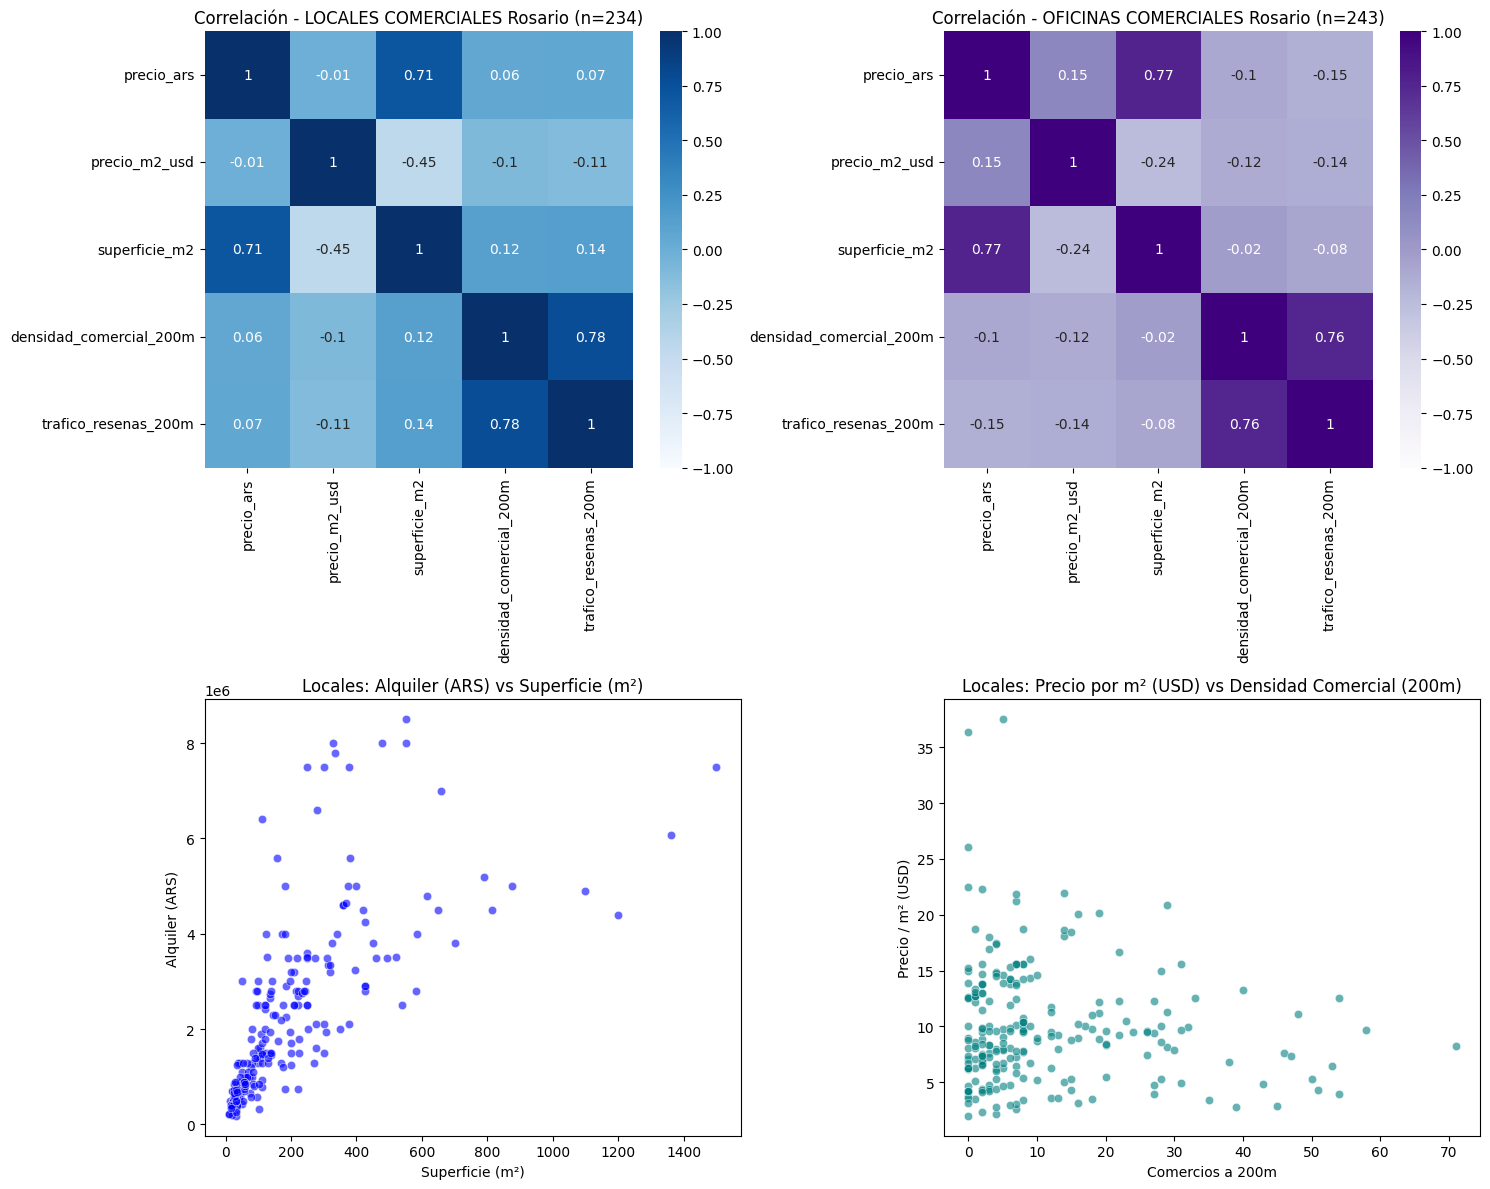

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar el dataset ya limpio y cruzado geoespacialmente
zp_clean = pd.read_csv("dataset_inmobiliario_completo_rosario.csv")

# 2. Separar Locales Comerciales vs Oficinas Comerciales
locales = zp_clean[zp_clean['tipo_inmueble'] == 'Locales Comerciales']
oficinas = zp_clean[zp_clean['tipo_inmueble'] == 'Oficinas comerciales']

print(f"Total propiedades analizadas: {len(zp_clean)} (Locales: {len(locales)} | Oficinas: {len(oficinas)})")
print(f"Cobertura a 200m: {(zp_clean['densidad_comercial_200m'] > 0).mean():.1%} | Cobertura a 350m: {(zp_clean['densidad_comercial_350m'] > 0).mean():.1%}\n")
print(zp_clean[['precio_ars', 'precio_usd', 'superficie_m2', 'precio_m2_usd', 'densidad_comercial_200m', 'trafico_resenas_200m']].describe().round(2))

# 3. Generar Dashboard EDA
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

corr_loc = locales[['precio_ars', 'precio_m2_usd', 'superficie_m2', 'densidad_comercial_200m', 'trafico_resenas_200m']].corr().round(2)
sns.heatmap(corr_loc, annot=True, cmap='Blues', ax=axes[0, 0], vmin=-1, vmax=1)
axes[0, 0].set_title(f"Correlación - LOCALES COMERCIALES Rosario (n={len(locales)})")

corr_ofi = oficinas[['precio_ars', 'precio_m2_usd', 'superficie_m2', 'densidad_comercial_200m', 'trafico_resenas_200m']].corr().round(2)
sns.heatmap(corr_ofi, annot=True, cmap='Purples', ax=axes[0, 1], vmin=-1, vmax=1)
axes[0, 1].set_title(f"Correlación - OFICINAS COMERCIALES Rosario (n={len(oficinas)})")

sns.scatterplot(data=locales, x='superficie_m2', y='precio_ars', alpha=0.6, ax=axes[1, 0], color='blue')
axes[1, 0].set_title("Locales: Alquiler (ARS) vs Superficie (m²)")
axes[1, 0].set_xlabel("Superficie (m²)")
axes[1, 0].set_ylabel("Alquiler (ARS)")

sns.scatterplot(data=locales, x='densidad_comercial_200m', y='precio_m2_usd', alpha=0.6, ax=axes[1, 1], color='teal')
axes[1, 1].set_title("Locales: Precio por m² (USD) vs Densidad Comercial (200m)")
axes[1, 1].set_xlabel("Comercios a 200m")
axes[1, 1].set_ylabel("Precio / m² (USD)")

plt.tight_layout()
plt.savefig('eda_dashboard_rosario_nuevo.png', dpi=150)
plt.show()

In [ ]:
import pandas as pd
import numpy as np

# 1. Leer el DATASET LIMPIO (Bloque 3 del diagrama)
df = pd.read_csv("dataset_inmobiliario_completo_rosario.csv")

# ==============================================================================
# BLOQUE 4: APIFY EDA -> Generación de tablas agregadas para gráficas
# ==============================================================================

# --- CSV 1 / HOJA 1: Resumen ejecutivo por Barrio y Tipo de Inmueble ---
csv1_barrios = (
    df.groupby(['barrio', 'tipo_inmueble'], as_index=False)
    .agg(
        cantidad_inmuebles=('posting_id', 'count'),
        alquiler_promedio_usd=('precio_usd', 'mean'),
        alquiler_mediana_usd=('precio_usd', 'median'),
        alquiler_promedio_ars=('precio_ars', 'mean'),
        precio_m2_promedio_usd=('precio_m2_usd', 'mean'),
        superficie_promedio_m2=('superficie_m2', 'mean'),
        densidad_comercial_200m_prom=('densidad_comercial_200m', 'mean'),
        trafico_resenas_200m_prom=('trafico_resenas_200m', 'mean')
    )
    .sort_values(by='cantidad_inmuebles', ascending=False)
    .round(2)
)

# --- CSV 2 / HOJA 2: Base geoespacial enriquecida para Mapa y Scatter en Looker ---
csv2_mapa = df[[
    'posting_id', 'barrio', 'ciudad', 'tipo_inmueble',
    'superficie_m2', 'precio_usd', 'precio_ars', 'precio_m2_usd',
    'densidad_comercial_200m', 'trafico_resenas_200m',
    'densidad_comercial_350m', 'trafico_resenas_350m', 'resenas_por_comercio_350m'
]].copy()

# Formato exacto "lat,lon" que pide Looker Studio para campos tipo Geo -> Latitud, Longitud
csv2_mapa['coordenadas_geo'] = df['lat'].astype(str) + "," + df['lon'].astype(str)

# Clasificación comercial del entorno para filtrar en el dashboard
csv2_mapa['entorno_comercial'] = pd.cut(
    csv2_mapa['densidad_comercial_200m'],
    bins=[-1, 4, 15, 30, 999],
    labels=['1. Bajo tránsito (<5)', '2. Tránsito medio (5-15)', '3. Corredor comercial (16-30)', '4. Polo Prime (>30)']
)

# --- CSV 3 / HOJA 3: Análisis por tramo de Densidad Comercial y Rango de Superficie ---
df['rango_superficie'] = pd.cut(
    df['superficie_m2'],
    bins=[0, 50, 120, 300, 2500],
    labels=['1. Chico (10-50 m²)', '2. Mediano (51-120 m²)', '3. Grande (121-300 m²)', '4. Gran Superficie (>300 m²)']
)
df['entorno_comercial'] = csv2_mapa['entorno_comercial']

csv3_segmentos = (
    df.groupby(['tipo_inmueble', 'entorno_comercial', 'rango_superficie'], observed=True, as_index=False)
    .agg(
        cantidad=('posting_id', 'count'),
        precio_promedio_usd=('precio_usd', 'mean'),
        precio_m2_usd=('precio_m2_usd', 'mean'),
        resenas_promedio_200m=('trafico_resenas_200m', 'mean')
    )
    .round(2)
)

# ==============================================================================
# BLOQUE 5: EXPORTAR A DRIVE (3 CSVs individuales + 1 XLSX con 3 hojas)
# ==============================================================================
csv1_barrios.to_csv("eda_csv1_resumen_barrios.csv", index=False, encoding="utf-8-sig")
csv2_mapa.to_csv("eda_csv2_mapa_propiedades.csv", index=False, encoding="utf-8-sig")
csv3_segmentos.to_csv("eda_csv3_segmentos_densidad.csv", index=False, encoding="utf-8-sig")

with pd.ExcelWriter("contenido_graficas_inmobify.xlsx", engine="openpyxl") as writer:
    csv1_barrios.to_excel(writer, sheet_name="hoja1_resumen_barrios", index=False)
    csv2_mapa.to_excel(writer, sheet_name="hoja2_mapa_propiedades", index=False)
    csv3_segmentos.to_excel(writer, sheet_name="hoja3_segmentos_densidad", index=False)

print("Generados los archivos del Bloque 5:")
print(f" - hoja1 / csv1: {len(csv1_barrios)} filas")
print(f" - hoja2 / csv2: {len(csv2_mapa)} filas")
print(f" - hoja3 / csv3: {len(csv3_segmentos)} filas")

Generados los archivos del Bloque 5:
 - hoja1 / csv1: 48 filas
 - hoja2 / csv2: 477 filas
 - hoja3 / csv3: 32 filas


Para recuperar los raw de las corridas

In [ ]:
import pandas as pd
from apify_client import ApifyClient

# Podés poner 1 token o los tokens de las cuentas que usaste para recuperar todos los runs
TOKENS_APIFY = [
    "apify_api_" # Eliminados por seguridad, reemplazá con tus tokens reales
]

# ==============================================================================
# 1. RECUPERAR RAW DE ZONAPROP (ÚLTIMA CORRIDA EXITOSA)
# ==============================================================================
client_principal = ApifyClient(TOKENS_APIFY[0])
last_run_zp = client_principal.actor("ecomscrape/zonaprop-property-listings-scraper").last_run(status="SUCCEEDED").get()
items_zp_raw = list(client_principal.dataset(last_run_zp.default_dataset_id).iterate_items())
df_zp_raw = pd.DataFrame(items_zp_raw)

df_zp_raw.to_csv("raw_zonaprop_rosario.csv", index=False, encoding="utf-8-sig")
print(f"Zonaprop RAW guardado ({len(df_zp_raw)} registros) desde run {last_run_zp.id}.")

# ==============================================================================
# 2. RECUPERAR Y UNIFICAR TODOS LOS RUNS DE GOOGLE MAPS (INCLUSO ABORTADOS)
# ==============================================================================
todos_items_gm = []

for idx, token in enumerate(TOKENS_APIFY):
    client = ApifyClient(token)
    runs_list = client.actor("compass/crawler-google-places").runs().list(limit=50).items
    print(f"Cuenta {idx+1}: encontradas {len(runs_list)} corridas de Google Maps.")

    for run_info in runs_list:
        dataset_id = run_info.default_dataset_id
        if dataset_id:
            try:
                items = list(client.dataset(dataset_id).iterate_items())
                if items:
                    print(f"  -> Run {run_info.id} ({run_info.status}): {len(items)} lugares recuperados")
                    todos_items_gm.extend(items)
            except Exception as e:
                print(f"  -> Run {run_info.id}: dataset expirado o no disponible ({e})")

# Unificar todas las tandas en un único RAW de Google Maps y deduplicar por placeId
df_gm_raw_unificado = pd.json_normalize(todos_items_gm, sep='/')
if 'placeId' in df_gm_raw_unificado.columns:
    df_gm_raw_unificado = df_gm_raw_unificado.drop_duplicates(subset=['placeId'], keep='last')

df_gm_raw_unificado.to_csv("raw_google_maps_rosario.csv", index=False, encoding="utf-8-sig")
print(f"\nGoogle Maps RAW unificado guardado: {len(df_gm_raw_unificado)} comercios únicos totales.")

Zonaprop RAW guardado (1079 registros) desde run Wk1FoBhifRT0Kmkiy.
Cuenta 1: encontradas 8 corridas de Google Maps.
  -> Run wwjahnmRiQxMfHTKC (SUCCEEDED): 96 lugares recuperados
  -> Run Ca4vR2NmSul73sotG (SUCCEEDED): 120 lugares recuperados
  -> Run dHt4Tk8XiXAh2zBDC (SUCCEEDED): 108 lugares recuperados
  -> Run j3S2JWrabvkE6mOzQ (SUCCEEDED): 240 lugares recuperados
  -> Run Qh7oNYGsMfxfPIh4s (SUCCEEDED): 348 lugares recuperados
  -> Run adIWnq4fXhgGg5kB5 (SUCCEEDED): 96 lugares recuperados
  -> Run Zt76p3M6Y5I9fshXs (SUCCEEDED): 96 lugares recuperados
  -> Run DnWzfNHCRI9yrdlcv (SUCCEEDED): 144 lugares recuperados
Cuenta 2: encontradas 8 corridas de Google Maps.
  -> Run IceuFOsdtPo6QqMQf (SUCCEEDED): 96 lugares recuperados
  -> Run jdMuCy8htNwo5hKbJ (SUCCEEDED): 108 lugares recuperados
  -> Run o8jEdY6zoYfdTE9lx (SUCCEEDED): 60 lugares recuperados
  -> Run kr8a8Oa4bYOhYsPtL (SUCCEEDED): 300 lugares recuperados
  -> Run G9oYCufWAI2P05NGC (SUCCEEDED): 96 lugares recuperados
  -> Run

Dataset cargado: 477 propiedades | 33 columnas

=== CORRELACIONES ORDENADAS CON precio_usd ===
precio_usd                  1.000
log_superficie_m2           0.773
superficie_m2               0.741
es_gran_superficie          0.689
precio_m2_usd               0.103
expensas_ars                0.028
intensidad_resenas_200m    -0.036
dist_monumento_m           -0.041
dist_pellegrini_m          -0.047
log_trafico_resenas_200m   -0.070
diversidad_rubros_200m     -0.071
dist_polo_mas_cercano_m    -0.080
densidad_comercial_200m    -0.085
ratio_densidad_200_350     -0.108
dist_pichincha_m           -0.128
tiene_expensas             -0.315
Name: precio_usd, dtype: float64

=== CORRELACIONES ORDENADAS CON precio_m2_usd ===
precio_m2_usd               1.000
dist_pellegrini_m           0.107
dist_monumento_m            0.104
precio_usd                  0.103
dist_polo_mas_cercano_m     0.038
dist_pichincha_m           -0.024
tiene_expensas             -0.025
expensas_ars               -0.034
ratio

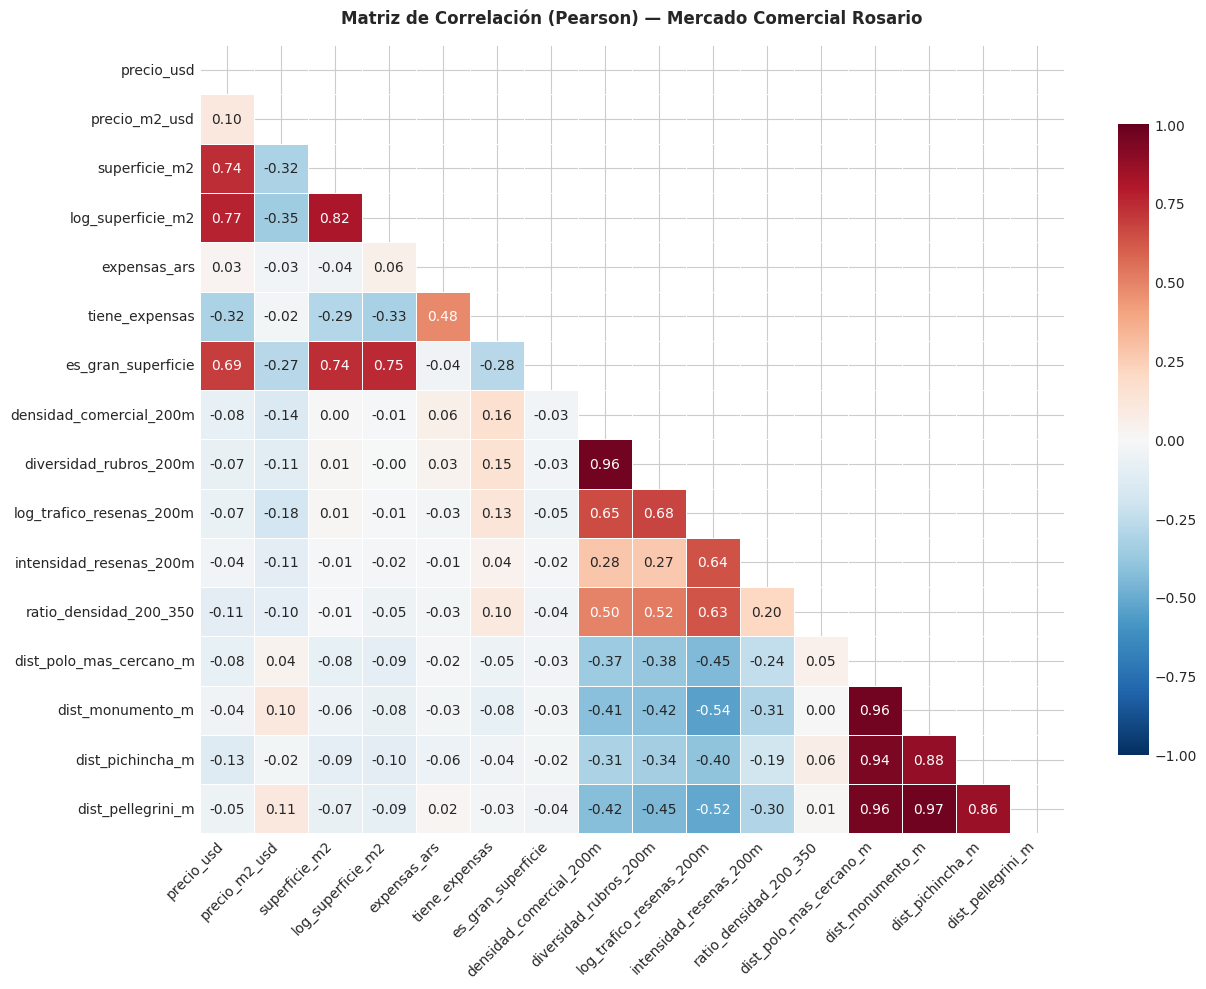

/tmp/ipykernel_460/951442472.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="tipo_inmueble", y="precio_m2_usd", ax=axes[0, 1], palette="Set2")
/tmp/ipykernel_460/951442472.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


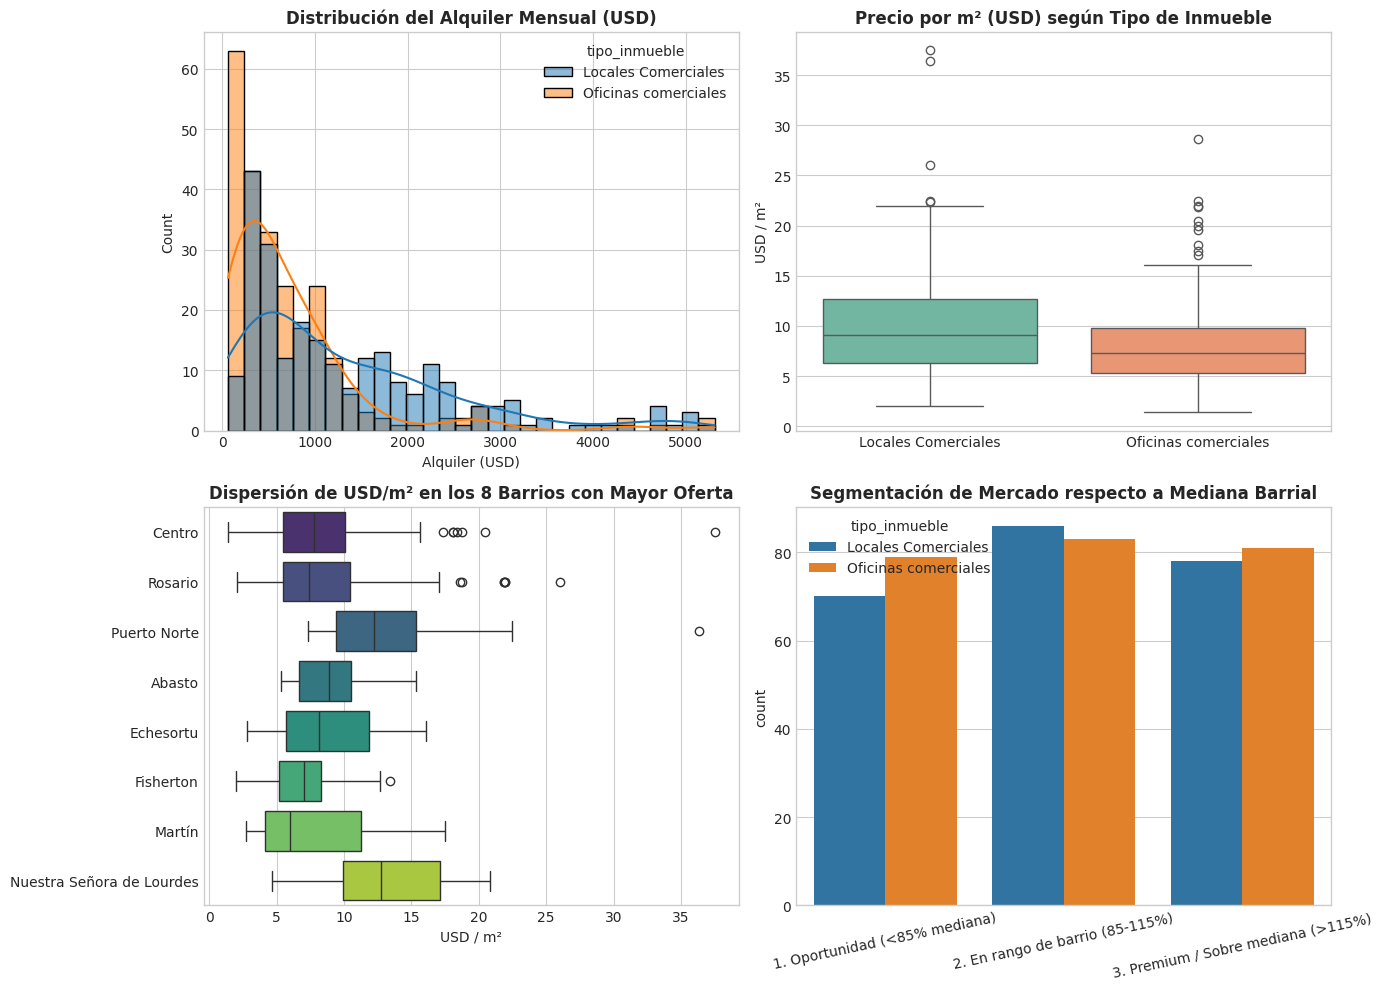

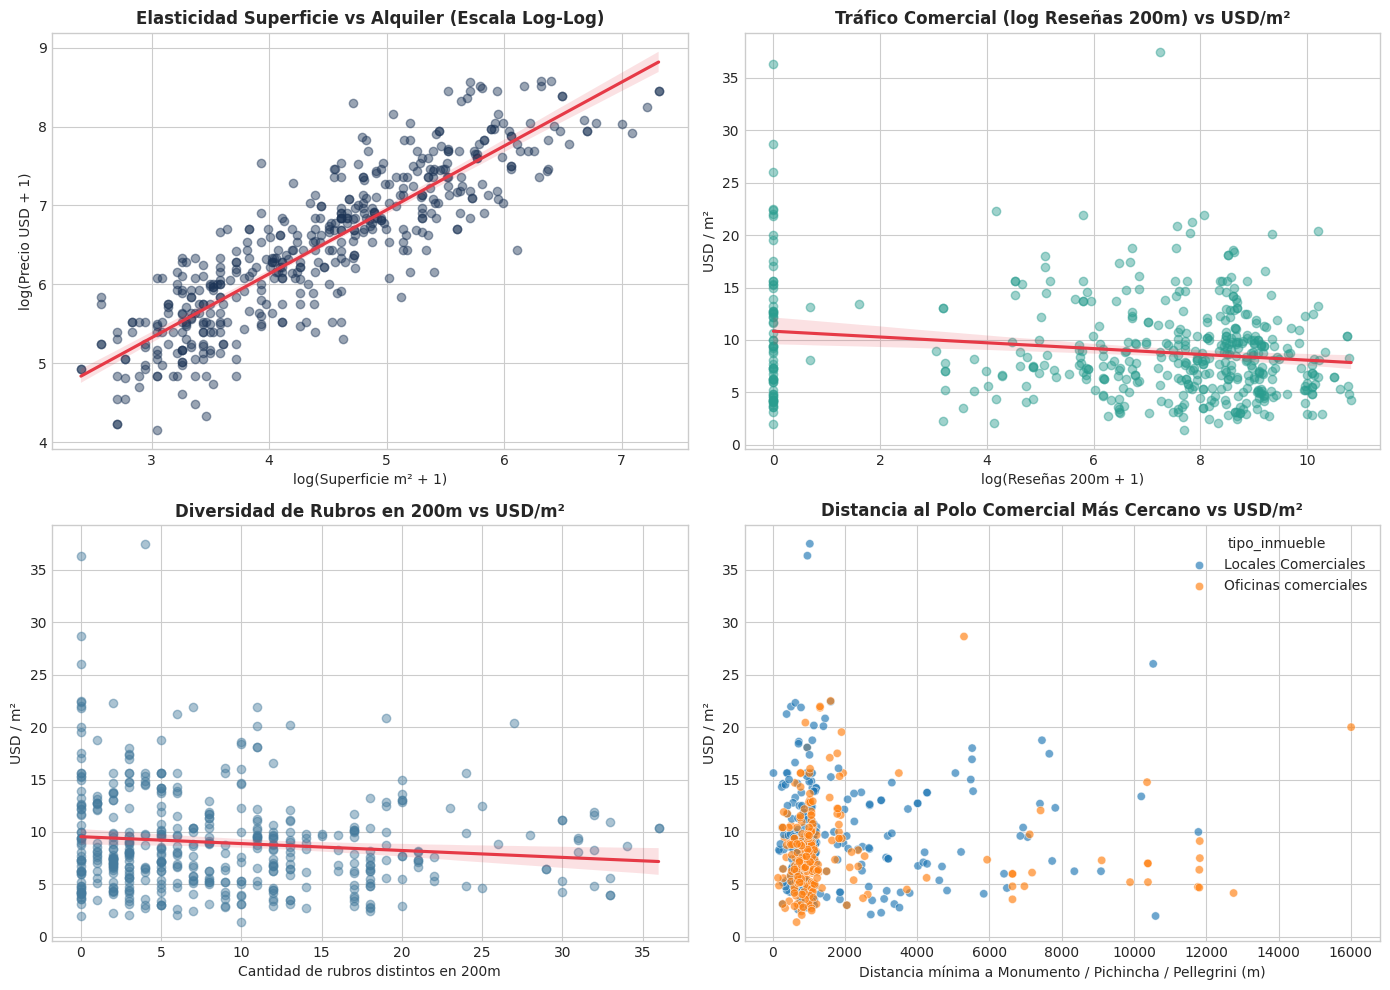

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo limpio para presentaciones e informes
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

df = pd.read_csv("dataset_inmobiliario_completo_rosario.txt")
print(f"Dataset cargado: {df.shape[0]} propiedades | {df.shape[1]} columnas")

# ------------------------------------------------------------------------------
# 1. MATRIZ DE CORRELACIÓN NUMÉRICA Y HEATMAP
# ------------------------------------------------------------------------------
cols_corr = [
    "precio_usd", "precio_m2_usd", "superficie_m2", "log_superficie_m2",
    "expensas_ars", "tiene_expensas", "es_gran_superficie",
    "densidad_comercial_200m", "diversidad_rubros_200m",
    "log_trafico_resenas_200m", "intensidad_resenas_200m",
    "ratio_densidad_200_350", "dist_polo_mas_cercano_m",
    "dist_monumento_m", "dist_pichincha_m", "dist_pellegrini_m"
]

corr_matrix = df[cols_corr].corr()

print("\n=== CORRELACIONES ORDENADAS CON precio_usd ===")
print(corr_matrix["precio_usd"].sort_values(ascending=False).round(3))

print("\n=== CORRELACIONES ORDENADAS CON precio_m2_usd ===")
print(corr_matrix["precio_m2_usd"].sort_values(ascending=False).round(3))

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax
)
ax.set_title("Matriz de Correlación (Pearson) — Mercado Comercial Rosario", pad=16)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("01_matriz_correlacion.png", dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# 2. DISTRIBUCIONES Y COMPARATIVA POR TIPO DE INMUEBLE Y BARRIO
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# A. Histograma precio_usd
sns.histplot(data=df, x="precio_usd", hue="tipo_inmueble", bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Distribución del Alquiler Mensual (USD)")
axes[0, 0].set_xlabel("Alquiler (USD)")

# B. Boxplot precio_m2_usd por tipo de inmueble
sns.boxplot(data=df, x="tipo_inmueble", y="precio_m2_usd", ax=axes[0, 1], palette="Set2")
axes[0, 1].set_title("Precio por m² (USD) según Tipo de Inmueble")
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("USD / m²")

# C. Top 8 barrios con más oferta (boxplot precio_m2_usd)
top_barrios = df["barrio"].value_counts().head(8).index
sns.boxplot(
    data=df[df["barrio"].isin(top_barrios)],
    y="barrio",
    x="precio_m2_usd",
    order=top_barrios,
    ax=axes[1, 0],
    palette="viridis"
)
axes[1, 0].set_title("Dispersión de USD/m² en los 8 Barrios con Mayor Oferta")
axes[1, 0].set_xlabel("USD / m²")
axes[1, 0].set_ylabel("")

# D. Posición de mercado respecto a la mediana del barrio
orden_pos = [
    "1. Oportunidad (<85% mediana)",
    "2. En rango de barrio (85-115%)",
    "3. Premium / Sobre mediana (>115%)"
]
sns.countplot(
    data=df,
    x="posicion_mercado_barrio",
    hue="tipo_inmueble",
    order=orden_pos,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Segmentación de Mercado respecto a Mediana Barrial")
axes[1, 1].set_xlabel("")
axes[1, 1].tick_params(axis="x", rotation=12)

plt.tight_layout()
plt.savefig("02_distribuciones_y_boxplots.png", dpi=300)
plt.show()

# ------------------------------------------------------------------------------
# 3. RELACIONES MULTIVARIABLES CLAVE (REGRESIÓN LINEAL Y COMERCIAL)
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.regplot(
    data=df, x="log_superficie_m2", y=np.log1p(df["precio_usd"]),
    scatter_kws={"alpha": 0.45, "color": "#1d3557"}, line_kws={"color": "#e63946"}, ax=axes[0, 0]
)
axes[0, 0].set_title("Elasticidad Superficie vs Alquiler (Escala Log-Log)")
axes[0, 0].set_xlabel("log(Superficie m² + 1)")
axes[0, 0].set_ylabel("log(Precio USD + 1)")

sns.regplot(
    data=df, x="log_trafico_resenas_200m", y="precio_m2_usd",
    scatter_kws={"alpha": 0.45, "color": "#2a9d8f"}, line_kws={"color": "#e63946"}, ax=axes[0, 1]
)
axes[0, 1].set_title("Tráfico Comercial (log Reseñas 200m) vs USD/m²")
axes[0, 1].set_xlabel("log(Reseñas 200m + 1)")
axes[0, 1].set_ylabel("USD / m²")

sns.regplot(
    data=df, x="diversidad_rubros_200m", y="precio_m2_usd",
    scatter_kws={"alpha": 0.45, "color": "#457b9d"}, line_kws={"color": "#e63946"}, ax=axes[1, 0]
)
axes[1, 0].set_title("Diversidad de Rubros en 200m vs USD/m²")
axes[1, 0].set_xlabel("Cantidad de rubros distintos en 200m")
axes[1, 0].set_ylabel("USD / m²")

sns.scatterplot(
    data=df, x="dist_polo_mas_cercano_m", y="precio_m2_usd",
    hue="tipo_inmueble", alpha=0.65, ax=axes[1, 1]
)
axes[1, 1].set_title("Distancia al Polo Comercial Más Cercano vs USD/m²")
axes[1, 1].set_xlabel("Distancia mínima a Monumento / Pichincha / Pellegrini (m)")
axes[1, 1].set_ylabel("USD / m²")

plt.tight_layout()
plt.savefig("03_relaciones_clave.png", dpi=300)
plt.show()

[INFO] Descargando 'dataset_inmobiliario_completo_rosario.csv' desde Apify (inmobify-storage)...
